# 08 · Red neuronal (TensorFlow/Keras) y comparación de modelos

**Pregunta:** ¿una red neuronal recurrente pronostica mejor que el modelo de árboles del notebook 06?

**Comparación justa:** mismo problema (cambio a 24 h de cloro, turbidez y pH; la turbidez en escala
logarítmica), mismas particiones, misma meta (`calidad_agua/metas.py`) y la misma información disponible. Lo
que cambia es cómo la recibe cada modelo:

| | Árboles (scikit-learn) | Red recurrente (Keras) |
|---|---|---|
| Entrada | ~84 resúmenes calculados a mano (medias, cambios, valores de hace *k* horas) | la **secuencia** de las últimas 48 h (23 variables por hora) |
| Modelo | `HistGradientBoostingRegressor`, uno por parámetro | **LSTM** de 48 unidades + capa densa, un solo modelo para los tres parámetros |
| Sensor | variable categórica | *embedding* de 4 dimensiones |

**Un ajuste que salió de las pruebas:** entrenar **solo con horas normales** (sin evento en la hora
pronosticada). Los cambios bruscos de los eventos no se pueden anticipar a 24 h; si el modelo los ve
al entrenar, intenta memorizarlos y empeora en el día a día. Los eventos los atiende el detector
(notebook 07). Para que la comparación sea justa, los árboles también se reentrenan así.

**Entradas y objetivos se limpian distinto, a propósito.** Las **entradas** se limpian solo con las
reglas que existen en operación (presión, rango físico y sensor pegado:
`calidad.lecturas_operativas`), porque en vivo no hay etiquetas de falla y el modelo tiene que
aprender a convivir con lecturas con deriva, picos o ruido. Los **objetivos** son el valor real,
limpio de fallas del sensor (`calidad.lecturas_validas`), porque lo que se quiere pronosticar es el
agua, no la falla del instrumento.

**La información de clima no es la misma en los dos modelos, a propósito.** Los árboles reciben el
pronóstico de lluvia de las próximas 24 h (notebook 06); la LSTM no, porque en las pruebas previas
el pronóstico mejoraba a la red en la época seca pero la empeoraba en la lluviosa (turbidez de 58 %
a 53 % en sep–dic 2025). Ninguno de los dos usa la época del año (notebook 06). La combinación
junta las dos cosas.

**Cómo se decide:** se comparan en **dos validaciones**, la oficial (ene–abr 2026, la época más
seca) y un bloque lluvioso dentro del entrenamiento (se entrena hasta ago 2025 y se evalúa en
sep–dic 2025), se elige el mejor modelo **por parámetro** según el promedio de las dos, y
recién después se evalúa una vez en **prueba**. Se incluye una tercera opción: la **combinación**
(promedio de los dos pronósticos), que suele ser más estable que cada modelo por separado.

In [1]:
import os, sys, time
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # oculta los mensajes internos de TensorFlow
sys.path.insert(0, str(Path.cwd().parent))          # por si calidad_agua no está instalado (pip install -e .)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras

from calidad_agua import carga, calidad, metas, modelo, variables, clima, red_neuronal as rn
from calidad_agua.graficos import estilo, guardar, COLORES, GRIS

estilo()
pd.set_option("display.precision", 1)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

crudo = carga.cargar_todo()
t15 = calidad.lecturas_operativas(crudo)        # ENTRADAS: limpieza que también existe en operación
t15_real = calidad.lecturas_validas(crudo)      # OBJETIVOS: valor real, sin fallas del sensor
h = variables.horario(t15)
h_real = variables.horario(t15_real)
pronostico = clima.ventanas(clima.cargar_pronostico(), h.index)    # para los árboles
tabla, tipicos = variables.tabla(h, horizonte=metas.HORIZONTE_H, h_objetivo=h_real, pronostico=pronostico)
X = variables.columnas_entrada(tabla)
datos = rn.preparar(h, tipicos, h_objetivo=h_real)                  # la LSTM, sin pronóstico ni época
PARAM = rn.SALIDAS
ETIQ = {"CL2": "Cloro libre", "TURB": "Turbidez", "PH": "pH"}
print(f"Secuencias: {len(datos['sensores'])} sensores × {len(datos['fechas']):,} horas × "
      f"{datos['secuencias'][0].shape[1]} variables por hora · ventana de {rn.VENTANA_H} h")
print("Variables por hora:", ", ".join(datos["variables"]))

Secuencias: 21 sensores × 17,520 horas × 21 variables por hora · ventana de 48 h
Variables por hora: CL2, TURB, PH, TEMP, P, hora_sin, hora_cos, lluvia, caudal, fuente_CL2, red_CL2, fuente_TURB, red_TURB, fuente_PH, red_PH, fuente_TEMP, red_TEMP, falta_CL2, falta_TURB, falta_PH, falta_TEMP


## 1. Red neuronal LSTM

Se entrena tres veces con distinta semilla aleatoria y se promedian los pronósticos. Una red
neuronal da resultados algo distintos en cada entrenamiento; promediar tres reduce esa variación y
muestra cuánto cambia de una vez a otra.

El entrenamiento se detiene cuando el error en una muestra de validación deja de bajar durante 2
épocas, y se conservan los pesos de la mejor época.

In [2]:
def entrenar_lstm(datos_, semillas=(0, 1, 2), mostrar=True):
    idx_entr = rn.indices(datos_, "entrenamiento", solo_normal=True)
    idx_parada = rn.indices(datos_, "validacion", solo_normal=True)[::3]
    redes_, historias_ = [], []
    for semilla in semillas:
        keras.utils.set_random_seed(semilla)
        red = rn.construir(datos_["secuencias"][0].shape[1], len(datos_["sensores"]))
        red.optimizer.learning_rate.assign(3e-4)
        t0 = time.time()
        hist = red.fit(rn.Lotes(datos_, idx_entr, 512, barajar=True, semilla=semilla),
                       validation_data=rn.Lotes(datos_, idx_parada, 2048), epochs=8, verbose=0,
                       callbacks=[keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)])
        redes_.append(red); historias_.append(hist.history)
        if mostrar:
            print(f"semilla {semilla}: {len(hist.history['loss'])} épocas, mejor la "
                  f"{int(np.argmin(hist.history['val_loss'])) + 1} · {time.time() - t0:.0f} s")
    return redes_, historias_

print(f"Ejemplos de entrenamiento: {len(rn.indices(datos, 'entrenamiento', solo_normal=True)):,}")
redes, historias = entrenar_lstm(datos)
redes[0].summary()

Ejemplos de entrenamiento: 226,801


semilla 0: 6 épocas, mejor la 4 · 186 s


semilla 1: 4 épocas, mejor la 2 · 116 s


semilla 2: 4 épocas, mejor la 2 · 121 s


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sensor (InputLayer) │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ secuencia           │ (None, 48, 21)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_sensor    │ (None, 1, 4)      │         84 │ sensor[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 48)        │     13,440 │ secuencia[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 4)         │          0 │ embedding_sensor… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tipicos             │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 55)        │          0 │ lstm[0][0],       │
│ (Concatenate)       │                   │            │ flatten[0][0],    │
│                     │                   │            │ tipicos[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 55)        │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      3,584 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cambio_24h (Dense)  │ (None, 3)         │        195 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 51,911 (202.78 KB)

 Trainable params: 17,303 (67.59 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 34,608 (135.19 KB)

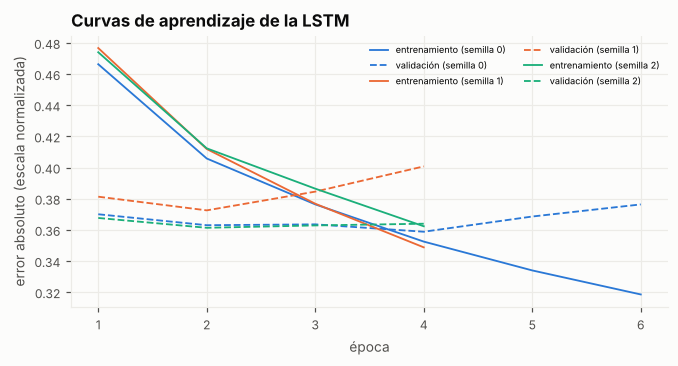

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, hst in enumerate(historias):
    ep = np.arange(1, len(hst["loss"]) + 1)
    ax.plot(ep, hst["loss"], color=COLORES[k], lw=1.2, label=f"entrenamiento (semilla {k})")
    ax.plot(ep, hst["val_loss"], color=COLORES[k], lw=1.2, ls="--", label=f"validación (semilla {k})")
ax.set_xlabel("época"); ax.set_ylabel("error absoluto (escala normalizada)")
ax.set_xticks(range(1, max(len(h_["loss"]) for h_ in historias) + 1))
ax.set_title("Curvas de aprendizaje de la LSTM")
ax.legend(fontsize=6, ncol=2)
guardar(fig, "08_curvas_aprendizaje"); plt.show()

## 2. Árboles, entrenados también solo con horas normales

In [4]:
def entrenar_arboles(tabla_, filas):
    return {p: modelo.entrenar(tabla_, p, X, filas & (tabla_["evento_objetivo"] == 0)) for p in PARAM}

entr = tabla["particion"] == "entrenamiento"
arboles = entrenar_arboles(tabla, entr)
print({p: m.n_iter_ for p, m in arboles.items()})

{'CL2': 400, 'TURB': 400, 'PH': 400}


## 3. Pronósticos de todos los modelos en las mismas filas

Para comparar en igualdad de condiciones, cada modelo pronostica exactamente los mismos pares
(sensor, hora).

In [5]:
def pronosticos(particion, datos=datos, redes=redes, arboles=arboles, tabla=tabla):
    idx = rn.indices(datos, particion)
    marco = pd.DataFrame({"nodo": np.array(datos["sensores"])[idx[:, 0]], "fecha": datos["fechas"][idx[:, 1]]})
    marco["evento"] = np.nan_to_num(datos["evento"][idx[:, 1] + metas.HORIZONTE_H, idx[:, 0]])
    lstm = np.mean([rn.pronosticar(r, datos, idx) for r in redes], axis=0)
    filas = marco.merge(tabla, on=["fecha", "nodo"], how="left", suffixes=("", "_t"))
    for k, p in enumerate(PARAM):
        marco[f"obs_{p}"] = filas[f"objetivo_{p}"].values
        marco[f"base_{p}"] = filas[p].values
        marco[f"arboles_{p}"] = modelo.pronosticar(arboles[p], filas, p, X)
        marco[f"lstm_{p}"] = lstm[:, k]
        if p == "TURB":   # en turbidez se promedia en escala logarítmica, coherente con la tolerancia relativa
            marco[f"combinado_{p}"] = np.exp((np.log(np.clip(marco[f"arboles_{p}"], 0.05, None)) +
                                              np.log(np.clip(marco[f"lstm_{p}"], 0.05, None))) / 2)
        else:
            marco[f"combinado_{p}"] = (marco[f"arboles_{p}"] + marco[f"lstm_{p}"]) / 2
    return marco

MODELOS = {"base": "línea base (igual que ayer)", "arboles": "árboles (scikit-learn)",
           "lstm": "LSTM (Keras)", "combinado": "combinación (promedio)"}

def tabla_acierto(marco, condicion="normal"):
    m = (marco["evento"] == 0) if condicion == "normal" else (marco["evento"] > 0)
    out = {}
    for clave, nombre in MODELOS.items():
        out[nombre] = {p: 100 * np.nanmean(metas.acierto(p, marco.loc[m, f"obs_{p}"],
                                                         marco.loc[m, f"{clave}_{p}"])[
                           marco.loc[m, f"{clave}_{p}"].notna() & marco.loc[m, f"base_{p}"].notna()])
                       for p in PARAM}
    return pd.DataFrame(out).T

pron_val = pronosticos("validacion")
acierto_val = tabla_acierto(pron_val)
acierto_val

,CL2,TURB,PH
línea base (igual que ayer),80.9,62.5,84.2
árboles (scikit-learn),90.3,72.6,89.6
LSTM (Keras),87.8,70.1,86.8
combinación (promedio),90.1,72.3,88.9


## 4. Elección por parámetro (dos validaciones)

Para cada parámetro se elige el modelo con mayor acierto en operación normal, en promedio entre la
validación oficial y el bloque lluvioso. Para el bloque lluvioso se repite todo el entrenamiento
(árboles, las tres redes, los valores típicos y la normalización) usando solo sep 2024 – ago 2025,
y se evalúa en sep–dic 2025.

In [6]:
# segunda validación: entrenar hasta ago 2025 y evaluar en sep–dic 2025
def bloque_lluvioso(h_):
    h_ = h_.copy()
    etiqueta = pd.Series("fuera", index=h_.index)
    etiqueta[(h_.index < "2025-09-01") & (h["particion"] == "entrenamiento")] = "entrenamiento"
    etiqueta[(h_.index >= "2025-09-01") & (h_.index < "2026-01-01")] = "validacion"
    h_["particion"] = etiqueta.values
    return h_

h_b, h_real_b = bloque_lluvioso(h), bloque_lluvioso(h_real)
tabla_b, tipicos_b = variables.tabla(h_b, horizonte=metas.HORIZONTE_H, h_objetivo=h_real_b, pronostico=pronostico)
datos_b = rn.preparar(h_b, tipicos_b, h_objetivo=h_real_b)
arboles_b = entrenar_arboles(tabla_b, tabla_b["particion"] == "entrenamiento")
redes_b, _ = entrenar_lstm(datos_b, mostrar=False)
acierto_lluvioso = tabla_acierto(pronosticos("validacion", datos_b, redes_b, arboles_b, tabla_b))

candidatos = ((acierto_val + acierto_lluvioso) / 2).drop(index=MODELOS["base"])
elegido = {p: candidatos[p].idxmax() for p in PARAM}
clave_elegida = {p: [k for k, v in MODELOS.items() if v == elegido[p]][0] for p in PARAM}
pd.concat({f"validación ({carga.texto_periodo('validacion')})": acierto_val,
           "bloque lluvioso (sep–dic 2025)": acierto_lluvioso,
           "promedio": (acierto_val + acierto_lluvioso) / 2}, axis=1).round(1)

validación (ene – abr 2026)             bloque lluvioso (sep–dic 2025)             promedio            
                                                    CL2  TURB    PH                            CL2  TURB    PH      CL2  TURB    PH
línea base (igual que ayer)                        80.9  62.5  84.2                           82.4  47.5  72.2     81.7  55.0  78.2
árboles (scikit-learn)                             90.3  72.6  89.6                           90.4  53.6  82.9     90.3  63.1  86.2
LSTM (Keras)                                       87.8  70.1  86.8                           87.3  57.2  80.9     87.5  63.7  83.8
combinación (promedio)                             90.1  72.3  88.9                           89.6  56.4  83.9     89.8  64.4  86.4

In [7]:
pd.Series(elegido, name="modelo elegido").to_frame()

,modelo elegido
CL2,árboles (scikit-learn)
TURB,combinación (promedio)
PH,combinación (promedio)


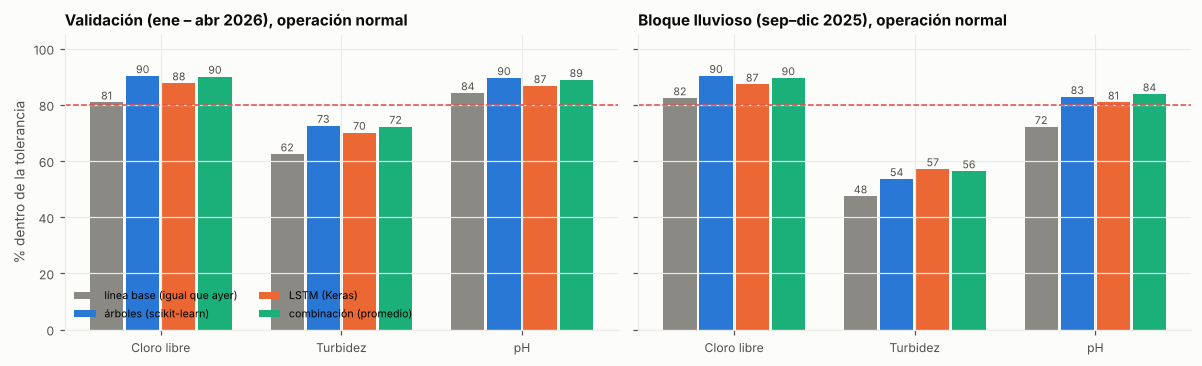

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
x = np.arange(len(PARAM)); ancho = 0.2
colores = {MODELOS["base"]: GRIS, MODELOS["arboles"]: COLORES[0], MODELOS["lstm"]: COLORES[1],
           MODELOS["combinado"]: COLORES[2]}
for ax, (titulo, acierto) in zip(axes, [(f"Validación ({carga.texto_periodo('validacion')})", acierto_val),
                                       ("Bloque lluvioso (sep–dic 2025)", acierto_lluvioso)]):
    for k, nombre in enumerate(MODELOS.values()):
        v = acierto.loc[nombre, PARAM].values
        barras = ax.bar(x + (k - 1.5) * ancho, v, ancho * 0.92, color=colores[nombre], label=nombre)
        for b_, v_ in zip(barras, v):
            ax.text(b_.get_x() + b_.get_width() / 2, v_ + 1, f"{v_:.0f}", ha="center", fontsize=7, color="#52514e")
    ax.axhline(metas.META_PCT, color=COLORES[7], ls="--", lw=1)
    ax.set_xticks(x); ax.set_xticklabels([ETIQ[p] for p in PARAM])
    ax.set_ylim(0, 105); ax.set_title(f"{titulo}, operación normal", fontsize=10)
axes[0].set_ylabel("% dentro de la tolerancia")
axes[0].legend(ncol=2, fontsize=7, loc="lower left")
fig.tight_layout()
guardar(fig, "08_comparacion_validacion"); plt.show()

## 5. Evaluación final en prueba

Con el modelo elegido para cada parámetro. Se muestran también los demás, como referencia, pero la
elección ya quedó fija en el paso anterior.

In [9]:
pron_prueba = pronosticos("prueba")
acierto_prueba = tabla_acierto(pron_prueba)
acierto_eventos = tabla_acierto(pron_prueba, "evento")
final = pd.DataFrame({
    "modelo elegido": elegido,
    "% acierto (normal)": {p: acierto_prueba.loc[elegido[p], p] for p in PARAM},
    "línea base": {p: acierto_prueba.loc[MODELOS["base"], p] for p in PARAM},
    "% acierto (eventos)": {p: acierto_eventos.loc[elegido[p], p] for p in PARAM},
})
final["cumple la meta"] = (final["% acierto (normal)"] >= metas.META_PCT) & (final["% acierto (normal)"] > final["línea base"])
final

,modelo elegido,% acierto (normal),línea base,% acierto (eventos),cumple la meta
CL2,árboles (scikit-learn),87.6,78.9,51.0,True
TURB,combinación (promedio),48.3,42.2,30.3,False
PH,combinación (promedio),83.3,77.6,62.6,True


In [10]:
acierto_prueba

,CL2,TURB,PH
línea base (igual que ayer),78.9,42.2,77.6
árboles (scikit-learn),87.6,49.9,84.2
LSTM (Keras),84.8,43.4,79.5
combinación (promedio),87.1,48.3,83.3


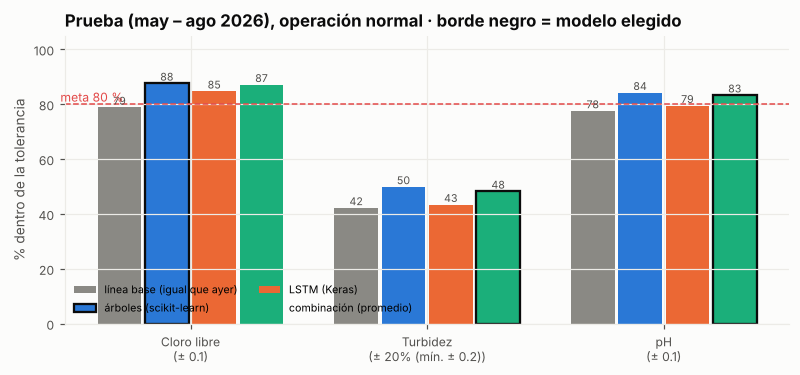

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
for k, nombre in enumerate(MODELOS.values()):
    v = acierto_prueba.loc[nombre, PARAM].values
    barras = ax.bar(x + (k - 1.5) * ancho, v, ancho * 0.92, color=colores[nombre], label=nombre,
                    edgecolor=["#0b0b0b" if elegido[p] == nombre else "none" for p in PARAM], linewidth=1.5)
    for b_, v_ in zip(barras, v):
        ax.text(b_.get_x() + b_.get_width() / 2, v_ + 1, f"{v_:.0f}", ha="center", fontsize=7, color="#52514e")
ax.axhline(metas.META_PCT, color=COLORES[7], ls="--", lw=1)
ax.text(-0.55, metas.META_PCT + 1, "meta 80 %", color=COLORES[7], fontsize=8, ha="left")
ax.set_xticks(x); ax.set_xticklabels([f"{ETIQ[p]}\n({metas.texto_tolerancia(p)})" for p in PARAM])
ax.set_ylim(0, 105); ax.set_ylabel("% dentro de la tolerancia")
ax.set_title(f"Prueba ({carga.texto_periodo('prueba')}), operación normal · borde negro = modelo elegido")
ax.legend(ncol=2, fontsize=7, loc="lower left")
guardar(fig, "08_resultado_prueba"); plt.show()

## 6. Guardar

In [12]:
carpeta = Path.cwd().parent / "modelos"
carpeta.mkdir(exist_ok=True)
for k, red in enumerate(redes):
    red.save(carpeta / f"lstm_24h_semilla{k}.keras")
import joblib
joblib.dump({"arboles": arboles, "columnas": X, "tipicos": tipicos, "elegido": clave_elegida,
             "normalizacion": datos["normalizacion"], "variables_lstm": datos["variables"],
             "redes": [f"lstm_24h_semilla{k}.keras" for k in range(len(redes))],
             # los árboles necesitan el pronóstico de lluvia de estos modelos meteorológicos, por tramos
             "pronostico_lluvia": {"modelos": clima.MODELOS, "columnas": clima.COLUMNAS},
             "lstm_opciones": {"epoca": False, "pronostico": False}},
            carpeta / "pronostico_24h_final.joblib", compress=3)
print("Modelo elegido por parámetro:", clave_elegida)

Modelo elegido por parámetro: {'CL2': 'arboles', 'TURB': 'combinado', 'PH': 'combinado'}


## 7. Conclusiones

**Resultado final en prueba (may–ago 2026, época lluviosa), operación normal**

| Parámetro | Modelo elegido (dos validaciones) | Acierto | Línea base | Antes (con época, sin pronóstico) | ¿Meta? |
|---|---|---|---|---|---|
| Cloro libre | árboles (scikit-learn) | **88 %** | 79 % | 86 % | **Sí** |
| Turbidez | combinación | 48 % | 42 % | 42 % | No |
| pH | combinación | **83 %** | 78 % | 80 % | **Sí** |

En las dos validaciones (promedio de la oficial, ene–abr 2026, y del bloque lluvioso, sep–dic
2025): cloro 90 %, turbidez 64 % y pH 86 %.

**Lo que muestra la comparación**

1. **Los árboles y la LSTM se complementan.**
   - Los **árboles**, que reciben el pronóstico de lluvia, son los mejores en la época seca y en
     cloro (90 % en las dos validaciones).
   - La **LSTM**, sin pronóstico, es la mejor en turbidez en el bloque lluvioso (57 % contra 54 % de
     los árboles): al ver la secuencia completa de las últimas 48 h de lluvia y de la fuente, sigue
     mejor cómo sube y baja la turbidez cuando ya está lloviendo.
   - La **combinación** junta las dos cosas y queda primera o casi primera en todo: se elige para
     turbidez y pH.
2. **La segunda validación cambió la elección.** Con solo la validación oficial (época seca) se
   habrían elegido los árboles para turbidez y pH; el bloque lluvioso muestra que la combinación
   es más robusta cuando llueve.
3. **En la prueba los árboles quedaron un poco mejor que la combinación** (turbidez 50 % contra
   48 %, pH 84 % contra 83 %). La diferencia es chica y la elección ya estaba fija: se reporta la
   combinación.
4. **La red neuronal se sobreajusta rápido.** En las curvas de aprendizaje el error de validación
   deja de bajar a las 2–4 épocas mientras el de entrenamiento sigue bajando. Hay pocos datos
   independientes (16 meses) para una red, aunque sea pequeña (17 687 parámetros). La parada
   temprana y el promedio de 3 entrenamientos lo controlan.
5. **La turbidez no llega al 80 % en la época lluviosa.** Quedó 6 puntos sobre la línea base, y el
   techo con lluvia perfecta (notebook 06) es 86–90 %: lo que falta es un pronóstico de lluvia más
   certero para una zona de aguaceros de tarde.
6. **Durante eventos los resultados no cambian mucho** (en prueba: cloro 51 %, pH 63 %, turbidez
   30 %), como se esperaba: es trabajo del detector.

**Sistema de pronóstico que queda**

- **Cloro:** árboles, con pronóstico de lluvia.
- **Turbidez y pH:** promedio de árboles (con pronóstico de lluvia) y LSTM (sin pronóstico), con la
  LSTM como promedio de 3 entrenamientos.
- Ninguno usa la época del año.

Queda guardado en `modelos/pronostico_24h_final.joblib`, más los tres archivos `.keras` de la red.
El archivo indica qué modelos meteorológicos y qué tramos de lluvia necesitan los árboles. El
servicio en tiempo real debe cargar este, no el del notebook 06.
